# Help Twitter Combat Hate Speech Using NLP and Machine Learning
Classify tweets as hate speech (label 1: racist or sexist) or not (label 0) with TF-IDF features and logistic regression, handling class imbalance and tuning with stratified 4-fold grid search on recall.

## Step 1: Load the tweets file with pandas `read_csv`

In [1]:
import re, json, os, random
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nltk
for p in ('stopwords', 'punkt', 'punkt_tab'): nltk.download(p, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import TweetTokenizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score, confusion_matrix
np.random.seed(42); os.makedirs('screens', exist_ok=True); RESULTS = {}
df = pd.read_csv('data/TwitterHate.csv')
print(df.shape); print(df.head())
print(df['label'].value_counts()); print(df['label'].value_counts(normalize=True).round(4))

(31962, 3)
   id  label                                              tweet
0   1      0   @user when a father is dysfunctional and is s...
1   2      0  @user @user thanks for #lyft credit i can't us...
2   3      0                                bihday your majesty
3   4      0  #model   i love u take with u all the time in ...
4   5      0             factsguide: society now    #motivation
label
0    29720
1     2242
Name: count, dtype: int64
label
0    0.9299
1    0.0701
Name: proportion, dtype: float64


The file has 31,962 tweets with columns `id`, `label` and `tweet`. Only about 7% of the tweets are hate speech, so the classes are heavily imbalanced; this matters for steps 9-11.

## Step 2: Get the tweets into a list for easy cleanup

In [2]:
tweets = df['tweet'].astype(str).tolist()
print(len(tweets)); print(tweets[:3])

31962
[' @user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction.   #run', "@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx.    #disapointed #getthanked", '  bihday your majesty']


## Step 3: Clean up the tweets
Each sub-step is applied in order: (a) lowercase, (b) remove `@handles`, (c) remove URLs, (d) tokenise with `TweetTokenizer`, (e) remove stop words, (f) remove redundant terms such as `amp` and `rt`, (g) strip `#` but keep the word.

In [3]:
stop = set(stopwords.words('english'))
redundant = {'amp', 'rt', 'user', 'via', 'u', 'ur'}   # 'user' is the placeholder the dataset uses for anonymised handles
tt = TweetTokenizer()

def step_a(t): return t.lower()                                  # (a) normalise casing
def step_b(t): return re.sub(r'@\w+', ' ', t)                    # (b) user handles
def step_c(t): return re.sub(r'(https?://\S+|www\.\S+)', ' ', t)  # (c) URLs
def step_g(tok): return tok.lstrip('#')                          # (g) drop '#', keep the text

def clean(t):
    t = step_c(step_b(step_a(t)))
    toks = tt.tokenize(t)                                        # (d) TweetTokenizer
    toks = [step_g(w) for w in toks]                             # (g)
    toks = [w for w in toks if w not in stop]                    # (e) stop words
    toks = [w for w in toks if w not in redundant]               # (f) redundant terms
    toks = [w for w in toks if len(w) > 1 and any(ch.isalnum() for ch in w)]   # Step 4: terms of length 1 removed (also drops pure-punctuation tokens such as '...')
    return toks
tokens = [clean(t) for t in tweets]
for i in range(3): print(tweets[i], '\n  ->', tokens[i])

 @user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction.   #run 
  -> ['father', 'dysfunctional', 'selfish', 'drags', 'kids', 'dysfunction', 'run']
@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx.    #disapointed #getthanked 
  -> ['thanks', 'lyft', 'credit', "can't", 'use', 'cause', 'offer', 'wheelchair', 'vans', 'pdx', 'disapointed', 'getthanked']
  bihday your majesty 
  -> ['bihday', 'majesty']


## Step 4: Remove terms with a length of 1
This filter is part of `clean()` above (`len(w) > 1`). It also removes lone punctuation marks and stray letters left by the tokeniser.

In [4]:
print('shortest remaining token length:', min((len(w) for t in tokens for w in t), default=0))
print('tweets that became empty:', sum(1 for t in tokens if not t))

shortest remaining token length: 2
tweets that became empty: 30


## Step 5: Check the top terms
(a) Collect all tokens in one list and (b) use `Counter` to get the 10 most common.

total tokens 247370 | vocabulary 42472
[('love', 2748), ('day', 2276), ('happy', 1684), ('time', 1131), ('life', 1118), ('like', 1047), ('today', 1013), ('new', 994), ('thankful', 946), ('positive', 931)]


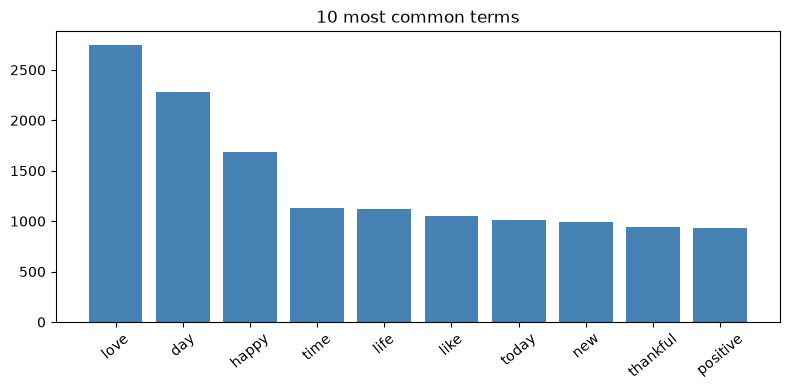

In [5]:
all_terms = [w for t in tokens for w in t]
cnt = Counter(all_terms)
print('total tokens', len(all_terms), '| vocabulary', len(cnt))
top10 = cnt.most_common(10); print(top10)
plt.figure(figsize=(8, 4)); plt.bar([w for w, _ in top10], [c for _, c in top10], color='steelblue'); plt.xticks(rotation=40); plt.title('10 most common terms'); plt.tight_layout()
plt.savefig('screens/01_top_terms.png', dpi=110); plt.show()
RESULTS['Top 10 terms'] = ', '.join(f'{w} ({c})' for w, c in top10)

## Step 6: Format the data for modelling
(a) Join tokens back into strings, (b) assign X and y, (c) `train_test_split` (stratified so both splits keep the 7% hate rate).

In [6]:
df['clean'] = [' '.join(t) for t in tokens]
X = df['clean']; y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, '| hate rate train/test:', round(y_train.mean(), 4), round(y_test.mean(), 4))

(23971,) (7991,) | hate rate train/test: 0.0701 0.0702


## Step 7: TF-IDF features
Import `TfidfVectorizer`, instantiate with at most 5000 terms, fit and apply on the train set, then only apply (transform) on the test set to avoid leakage.

In [7]:
tfidf = TfidfVectorizer(max_features=5000)
Xtr = tfidf.fit_transform(X_train); Xte = tfidf.transform(X_test)
print(Xtr.shape, Xte.shape)

(23971, 5000) (7991, 5000)


## Step 8: Ordinary logistic regression
Default parameters, fitted on the training data, predicting on train and test.

In [8]:
lr = LogisticRegression()
lr.fit(Xtr, y_train)
p_tr, p_te = lr.predict(Xtr), lr.predict(Xte)

## Step 9: Evaluate (accuracy, recall, F1)
Train-set metrics are requested; test metrics are shown for comparison.

In [9]:
def report(name, ytr, ptr, yte, pte):
    r = dict(acc_tr=accuracy_score(ytr, ptr), rec_tr=recall_score(ytr, ptr), f1_tr=f1_score(ytr, ptr), acc_te=accuracy_score(yte, pte), rec_te=recall_score(yte, pte), f1_te=f1_score(yte, pte), prec_te=precision_score(yte, pte))
    print(name, {k: round(v, 4) for k, v in r.items()}); return r
r_plain = report('plain LR', y_train, p_tr, y_test, p_te)

plain LR {'acc_tr': 0.955, 'rec_tr': 0.3789, 'f1_tr': 0.5414, 'acc_te': 0.9498, 'rec_te': 0.3173, 'f1_te': 0.4703, 'prec_te': 0.9082}


In [10]:
rec = r_plain['rec_tr']
print('Train accuracy %.4f | train recall %.4f -> recall is %s | train F1 %.4f' % (r_plain['acc_tr'], rec, 'low' if rec < 0.5 else ('decent' if rec < 0.75 else 'high'), r_plain['f1_tr']))

Train accuracy 0.9550 | train recall 0.3789 -> recall is low | train F1 0.5414


Accuracy looks excellent (about 95%) only because 93% of tweets are non-hate. Recall on the hate class is **low**, so the model misses most hate tweets. Accuracy is a misleading metric here.

## Step 10: Adjust the class imbalance
Set `class_weight='balanced'` on the logistic regression so errors on the rare hate class are weighted about 13 times more.

## Step 11: Train again with the adjustment and evaluate

In [11]:
lr_bal = LogisticRegression(class_weight='balanced')
lr_bal.fit(Xtr, y_train)
r_bal = report('balanced LR', y_train, lr_bal.predict(Xtr), y_test, lr_bal.predict(Xte))

balanced LR {'acc_tr': 0.9488, 'rec_tr': 0.9661, 'f1_tr': 0.7256, 'acc_te': 0.9239, 'rec_te': 0.779, 'f1_te': 0.5897, 'prec_te': 0.4745}


Recall rises sharply and F1 improves, at the cost of lower accuracy and precision: the model now flags more tweets as hate, including some false alarms. For a moderation use case, high recall is usually the priority.

## Step 12: Regularization and hyperparameter tuning
Import `GridSearchCV` and `StratifiedKFold`, grid over `C` and `penalty`, and use balanced class weights. `liblinear` supports both L1 and L2 penalties.

In [12]:
param_grid = {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2']}
base = LogisticRegression(class_weight='balanced', solver='liblinear', max_iter=1000)
print(param_grid)

{'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2']}


## Step 13: Find the parameters with the best recall in cross-validation
Scoring is `recall`, with stratified 4-fold cross-validation, fitted on the training set.

In [13]:
skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)
grid = GridSearchCV(base, param_grid, scoring='recall', cv=skf, n_jobs=-1, return_train_score=True)
grid.fit(Xtr, y_train)
res = pd.DataFrame(grid.cv_results_)[['param_C', 'param_penalty', 'mean_test_score', 'std_test_score', 'mean_train_score']].sort_values('mean_test_score', ascending=False)
print(res.to_string(index=False))

C:\Users\heman\.slvenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


 param_C param_penalty  mean_test_score  std_test_score  mean_train_score
    1.00            l2         0.773930        0.020135          0.976601
    0.10            l2         0.771552        0.022892          0.910767
   10.00            l2         0.741207        0.028784          0.995836
    1.00            l1         0.735860        0.018518          0.978782
   10.00            l1         0.706703        0.022642          0.997422
    0.01            l2         0.706097        0.045666          0.818960
  100.00            l2         0.700748        0.026671          0.997621
  100.00            l1         0.675161        0.039290          0.997621
    0.10            l1         0.584152        0.047848          0.633549
    0.01            l1         0.076190        0.044544          0.088224


## Step 14: List the best parameters

In [14]:
print('best params:', grid.best_params_, '| best CV recall: %.4f' % grid.best_score_)
RESULTS['Best params'] = str(grid.best_params_); RESULTS['Best CV recall'] = round(float(grid.best_score_), 4)

best params: {'C': 1, 'penalty': 'l2'} | best CV recall: 0.7739


The best setting is C=1 with an L2 penalty (CV recall about 0.77); C=0.1 with L2 is almost as good. L1 with very strong regularisation (C=0.01) collapses to near-zero recall, and weakly regularised models (C=10-100) overfit (train recall near 1.0, CV recall lower). Recall alone does not penalise false alarms, so Step 15 also reports precision and F1 on the unseen test set.

## Step 15: Evaluate the best estimator on the test set
Recall on the toxic (hate) class and F1 score.

best estimator on TEST: recall 0.7790  F1 0.5909  precision 0.4760  accuracy 0.9243
[[6949  481]
 [ 124  437]]


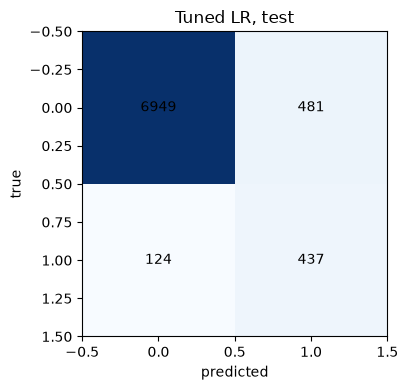

In [15]:
best = grid.best_estimator_
pb = best.predict(Xte)
rec_b, f1_b, prec_b, acc_b = recall_score(y_test, pb), f1_score(y_test, pb), precision_score(y_test, pb), accuracy_score(y_test, pb)
print('best estimator on TEST: recall %.4f  F1 %.4f  precision %.4f  accuracy %.4f' % (rec_b, f1_b, prec_b, acc_b))
print(confusion_matrix(y_test, pb))
fig, ax = plt.subplots(figsize=(4.5, 4)); ax.imshow(confusion_matrix(y_test, pb), cmap='Blues')
for (i, j), v in np.ndenumerate(confusion_matrix(y_test, pb)): ax.text(j, i, v, ha='center', va='center')
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title('Tuned LR, test'); plt.tight_layout(); plt.savefig('screens/02_confusion_matrix.png', dpi=110); plt.show()

## Final metrics table

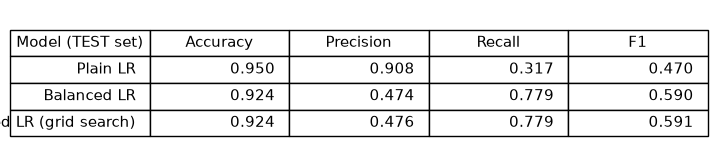

{'Top 10 terms': 'love (2748), day (2276), happy (1684), time (1131), life (1118), like (1047), today (1013), new (994), thankful (946), positive (931)', 'Best params': "{'C': 1, 'penalty': 'l2'}", 'Best CV recall': 0.7739, 'Train metrics plain LR (acc/recall/F1)': '0.9550 / 0.3789 / 0.5414', 'Train metrics balanced LR (acc/recall/F1)': '0.9488 / 0.9661 / 0.7256', 'Metrics': {'columns': ['Model (TEST set)', 'Accuracy', 'Precision', 'Recall', 'F1'], 'rows': [['Plain LR', '0.950', '0.908', '0.317', '0.470'], ['Balanced LR', '0.924', '0.474', '0.779', '0.590'], ['Tuned LR (grid search)', '0.924', '0.476', '0.779', '0.591']]}}


In [16]:
rows = [['Plain LR', f"{r_plain['acc_te']:.3f}", f"{r_plain['prec_te']:.3f}", f"{r_plain['rec_te']:.3f}", f"{r_plain['f1_te']:.3f}"],
        ['Balanced LR', f"{r_bal['acc_te']:.3f}", f"{r_bal['prec_te']:.3f}", f"{r_bal['rec_te']:.3f}", f"{r_bal['f1_te']:.3f}"],
        ['Tuned LR (grid search)', f'{acc_b:.3f}', f'{prec_b:.3f}', f'{rec_b:.3f}', f'{f1_b:.3f}']]
cols = ['Model (TEST set)', 'Accuracy', 'Precision', 'Recall', 'F1']
fig, ax = plt.subplots(figsize=(9, 1.9)); ax.axis('off')
t = ax.table(cellText=rows, colLabels=cols, loc='center'); t.scale(1, 1.6); t.auto_set_font_size(False); t.set_fontsize(11)
plt.savefig('screens/03_metrics_table.png', dpi=130, bbox_inches='tight'); plt.show()
RESULTS['Train metrics plain LR (acc/recall/F1)'] = '%.4f / %.4f / %.4f' % (r_plain['acc_tr'], r_plain['rec_tr'], r_plain['f1_tr'])
RESULTS['Train metrics balanced LR (acc/recall/F1)'] = '%.4f / %.4f / %.4f' % (r_bal['acc_tr'], r_bal['rec_tr'], r_bal['f1_tr'])
RESULTS['Metrics'] = {'columns': cols, 'rows': rows}
json.dump(RESULTS, open('results.json', 'w'), indent=1); print(RESULTS)

## Conclusion
Imbalance handling matters far more than the choice of regulariser: the plain model has high accuracy but low recall (about 0.32 on test), while the balanced and tuned models reach recall of about 0.78 at the cost of precision (about 0.47). Tuning with C and penalty gave essentially the same test result as simply balancing the classes. Next steps would be n-gram features, a probability threshold tuned for a precision/recall target, and a transformer model.